# 01 vs 01b Funnel step conversion: full window vs clean tracking window

- **01 Full window** (`results/01_funnel_by_device.csv`): all dates, includes the Nov 1-25 add_to_cart tracking outage.
- **01b Clean window** (`results/01b_funnel_clean_window.csv`): 2020-11-26 to 2021-01-31.

All-devices row. Only view → cart should move if the outage was the cause.

Rates are computed from the raw step counts (`s0_sessions` ... `s5_purchase`), not the
4-decimal `cr_*` columns, so labels and the change in points are not double-rounded.

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

# The project root is one level up from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

def results_path(name):
    return ROOT / "results" / name


In [2]:
import matplotlib.pyplot as plt

INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
})


In [3]:
STEPS = {
    "cr_session_to_view":     "Session to\nview item",
    "cr_view_to_cart":        "View item to\nadd to cart",
    "cr_cart_to_checkout":    "Add to cart to\nbegin checkout",
    "cr_checkout_to_payment": "Begin checkout to\nadd payment",
    "cr_payment_to_purchase": "Add payment to\npurchase",
}

COUNTS = ["s0_sessions", "s1_view_item", "s2_add_to_cart",
          "s3_begin_checkout", "s4_add_payment", "s5_purchase"]

def all_devices(name):
    """Step conversion = count at step k+1 / count at step k, from raw counts."""
    d = pd.read_csv(results_path(name))
    n = d.loc[d["device_group"] == "All devices", COUNTS].iloc[0].astype(float).to_numpy()
    return pd.Series(n[1:] / n[:-1], index=list(STEPS))

comp = pd.DataFrame({
    "Full window (01)": all_devices("01_funnel_by_device.csv"),
    "Clean window (01b)": all_devices("01b_funnel_clean_window.csv"),
})
comp["change_pts"] = (comp.iloc[:, 1] - comp.iloc[:, 0]) * 100
comp

,Full window (01),Clean window (01b),change_pts
cr_session_to_view,0.213868,0.204715,-0.915252
cr_view_to_cart,0.197001,0.262459,6.545823
cr_cart_to_checkout,0.392737,0.389099,-0.363845
cr_checkout_to_payment,0.647424,0.654552,0.712781
cr_payment_to_purchase,0.738206,0.741779,0.357265


saved 01b_funnel_comparison.png


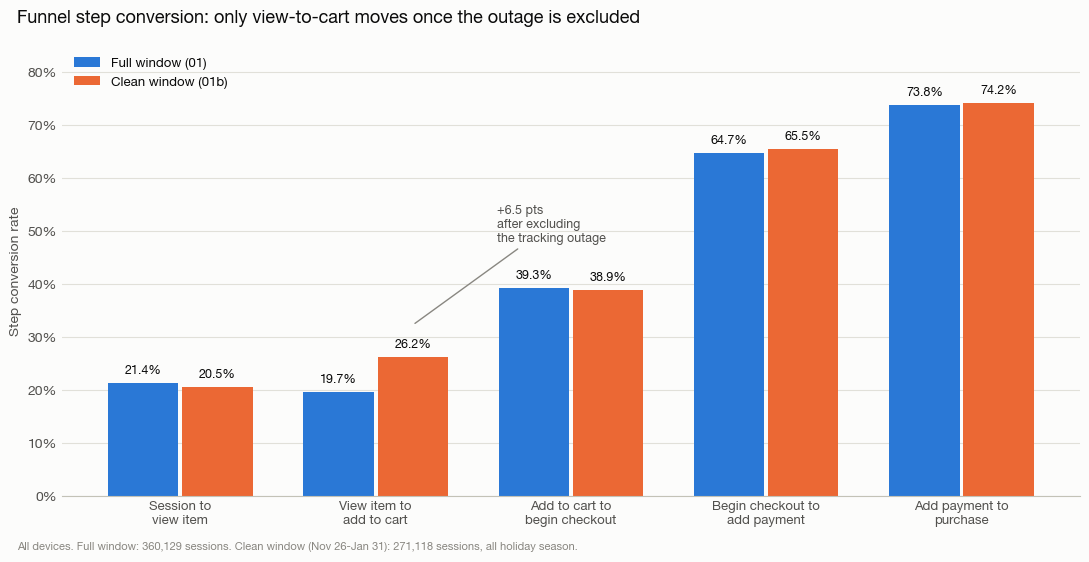

In [4]:
SERIES = {"Full window (01)": "#2a78d6", "Clean window (01b)": "#eb6834"}

fig, ax = plt.subplots(figsize=(11, 5.6))
x = np.arange(len(STEPS))
w = 0.36

for k, (name, color) in enumerate(SERIES.items()):
    vals = comp[name].to_numpy()
    bars = ax.bar(x + (k - 0.5) * (w + 0.02), vals, w, color=color, label=name, zorder=2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.1%}",
                ha="center", va="bottom", fontsize=9, color=INK)

# Call out the one step that moved.
i = list(STEPS).index("cr_view_to_cart")
ax.annotate(f"+{comp['change_pts'].iloc[i]:.1f} pts\nafter excluding\nthe tracking outage",
            xy=(i + 0.19, comp.iloc[i, 1] + 0.06), xytext=(i + 0.62, 0.48),
            fontsize=9, color=INK_2, ha="left",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))

ax.set_xticks(x)
ax.set_xticklabels(STEPS.values(), fontsize=9.5)
ax.set_ylim(0, 0.85)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Step conversion rate")
ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
ax.tick_params(length=0)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.legend(frameon=False, loc="upper left", fontsize=9.5)

fig.suptitle("Funnel step conversion: only view-to-cart moves once the outage is excluded",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.015,
         "All devices. Full window: 360,129 sessions. Clean window (Nov 26-Jan 31): 271,118 sessions, "
         "all holiday season.", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))

out = results_path("01b_funnel_comparison.png")
fig.savefig(out, dpi=200, facecolor=SURFACE)
print("saved", out.name)